# Punto 1 — Clasificación de transacciones fraudulentas

## 1. Exploración y organización de los datos

### Objetivo

Analizar la base de datos de transacciones bancarias
para identificar sus características, distribución de
clases y posibles dificultades para el entrenamiento
de modelos de clasificación supervisada.

La base de datos contiene transacciones legítimas
y fraudulentas. El principal desafío consiste en
identificar correctamente las operaciones fraudulentas,
que representan una proporción muy pequeña del total.

### Actividades

- Cargar la base de datos.
- Identificar las variables y la clase objetivo.
- Verificar valores nulos.
- Analizar la distribución de las clases.
- Examinar el desbalance.
- Explicar su impacto en los modelos de clasificación.

In [1]:
from pathlib import Path
import sys

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Localizar la raíz del proyecto
directorio = Path.cwd().resolve()

if (directorio / "src").is_dir():
    RAIZ = directorio
elif (directorio.parent / "src").is_dir():
    RAIZ = directorio.parent
else:
    raise RuntimeError(
        "No se encontró la carpeta src del proyecto"
    )

# Permitir importar módulos desde src
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

print("Proyecto:", RAIZ)
print("Python:", sys.executable)

Proyecto: C:\Users\Santiago\Documents\Santiago\Proyectos\Proyecto_Machine_Learning
Python: c:\Users\Santiago\Documents\Santiago\Proyectos\Proyecto_Machine_Learning\.venv\Scripts\python.exe


In [2]:
ruta_datos = RAIZ / "data" / "raw" / "creditcard.csv"

df = pd.read_csv(ruta_datos)

print("Dimensiones:", df.shape)
print("Total de registros:", len(df))
print("Total de características:", df.shape[1] - 1)

display(df.head())

Dimensiones: (284807, 31)
Total de registros: 284807
Total de características: 30


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [3]:

print("=== VALORES NULOS ===")
print(df.isnull().sum().sum())

print("\n=== DISTRIBUCIÓN DE CLASES ===")

distribucion = df["Class"].value_counts().sort_index()

porcentajes = (
    df["Class"].value_counts(normalize=True)
    .sort_index() * 100
)

tabla_clases = pd.DataFrame({
    "Cantidad": distribucion,
    "Porcentaje (%)": porcentajes.round(4)
})

tabla_clases.index = [
    "Legítima (0)",
    "Fraude (1)"
]

display(tabla_clases)


=== VALORES NULOS ===
0

=== DISTRIBUCIÓN DE CLASES ===


,Cantidad,Porcentaje (%)
Legítima (0),284315,99.8273
Fraude (1),492,0.1727


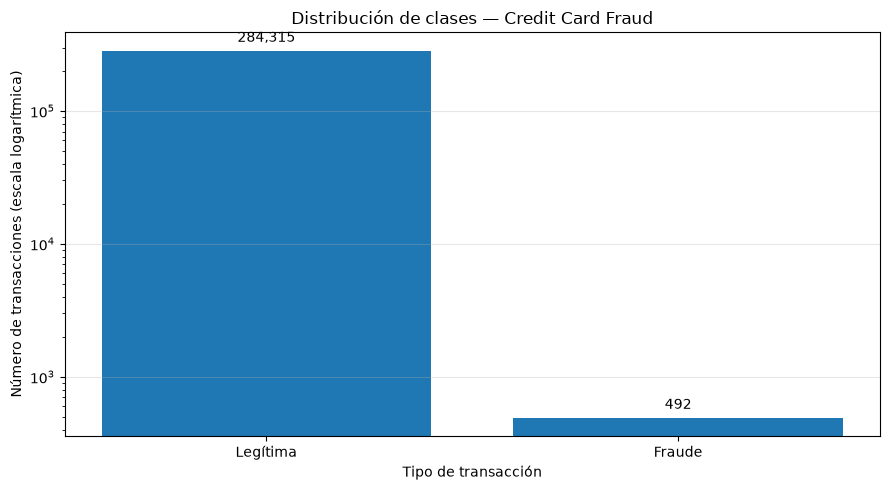

In [4]:
fig, ax = plt.subplots(figsize=(9, 5))

etiquetas = ["Legítima", "Fraude"]
cantidades = distribucion.values

barras = ax.bar(
    etiquetas,
    cantidades
)

ax.bar_label(
    barras,
    labels=[f"{n:,}" for n in cantidades],
    padding=4
)

ax.set_yscale("log")

ax.set_title(
    "Distribución de clases — Credit Card Fraud"
)
ax.set_ylabel("Número de transacciones (escala logarítmica)")
ax.set_xlabel("Tipo de transacción")

ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


## 2. Interpretación del análisis exploratorio

La base de datos contiene 284.807 transacciones,
de las cuales únicamente 492 corresponden a fraudes,
equivalentes aproximadamente al 0,173 % del total.

Esto demuestra que existe un desbalance extremo
entre las clases.

### ¿Por qué es importante?

Si un modelo clasificara todas las operaciones
como legítimas, podría alcanzar una exactitud
superior al 99 %, pero no detectaría ningún fraude.

Por esta razón, la exactitud no será suficiente
para determinar qué modelo funciona mejor.

Durante la evaluación también consideraremos:

- **Precisión:** proporción de alertas de fraude correctas.
- **Sensibilidad:** proporción de fraudes detectados.
- **Especificidad:** proporción de transacciones legítimas reconocidas.
- **F1-score:** equilibrio entre precisión y sensibilidad.

### Conclusión

El fuerte desbalance representa el principal desafío
de clasificación. Por ello, utilizaremos particiones
estratificadas y métricas que permitan evaluar el
desempeño de la clase minoritaria.
